In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from utils import (create_transition_open, get_complete_DR, make_maze,
                   evaluate_planning, evaluate_planning_barrier_crossing,
                   plan_with_D)

In [2]:
ROWS, COLS = 20, 20
NUM_STATES = ROWS * COLS
BARRIER_TYPE = 'H'
d = 400

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False

In [3]:
def woodbury(T_old, D, T_new):
    """
    Performs woodbury update in full space (ground truth).
    """
    diffs = T_old != T_new
    diff_rows, _ = np.where(diffs)
    delta_locs = np.unique(diff_rows)

    N = T_old.shape[0]
    R = (T_new - T_old)[delta_locs, :]
    C = np.eye(N)[:, delta_locs]

    Z = R @ D @ C
    A = np.linalg.inv(np.eye(Z.shape[0]) - Z)
    woodbury_update = D @ C @ A @ R @ D

    D_new = D + woodbury_update
    return D_new, R, C, delta_locs

In [ ]:
# === Setup ===
T_os = create_transition_open(shape=(ROWS, COLS))
D_os = get_complete_DR(T=T_os)
T_new, barrier_states = make_maze(T_os, BARRIER_TYPE, ROWS, COLS)
D_new, R, C, delta_locs = woodbury(T_os, D_os, T_new)
num_affected = len(delta_locs)

# === Build absorbed eigenbasis ===
eigenvalues, eigvecs = np.linalg.eigh(D_os)
idx = np.argsort(eigenvalues)[::-1][:d]
V = eigvecs[:, idx]
lam = eigenvalues[idx]
# lam = np.maximum(eigenvalues[idx], 1e-10)  # clip negative numerics
print(f"Min eigenvalue: {eigenvalues.min()}")
print(f"Num negative:   {np.sum(eigenvalues < 0)}")

# Absorb eigenvalues: U_os = V * sqrt(eigenvalues)
U_os = V * np.sqrt(lam)[np.newaxis, :]  # S x d

# Verify reconstruction quality
D_os_reconstructed = U_os @ U_os.T
recon_error = np.linalg.norm(D_os - D_os_reconstructed) / np.linalg.norm(D_os)
print(f"D_os reconstruction error with d={d}: {recon_error:.6f}")

print("Symmetry check:", np.max(np.abs(D_os - D_os.T)))
print("Reconstruction with V @ diag(lam) @ V.T:", 
      np.linalg.norm(D_os - V @ np.diag(lam) @ V.T) / np.linalg.norm(D_os))

Min eigenvalue: 0.34389859586520216
Num negative:   0
D_os reconstruction error with d=400: 0.077039


Text(0, 0.5, 'Value')

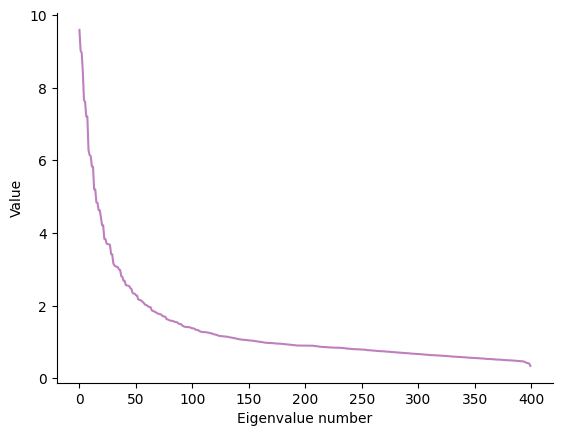

In [9]:
plt.plot(lam, color='purple', alpha=0.5)
plt.xlabel('Eigenvalue number')
plt.ylabel('Value')